In [35]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [36]:
df = pd.read_csv(r"C:\Users\MSII\OneDrive\Desktop\employee-attrition-prediction\data\processed\employee_attrition_clean.csv")

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (1470, 31)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,...,3,1,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,...,4,4,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,...,3,2,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,...,3,3,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,...,3,4,1,6,3,3,2,2,2,2


In [37]:
X = df.drop(columns=["Attrition"])

y = df["Attrition"].map({
    "No": 0,
    "Yes": 1
})

Data validate

In [38]:
assert X.shape[0] == y.shape[0]
assert y.notna().all()

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1470, 30)
Target shape: (1470,)


Train-Test Split

In [39]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [40]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1176, 30)
X_test: (294, 30)
y_train: (1176,)
y_test: (294,)


Class distribution verify

In [41]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).sort_index())

Training target distribution:
Attrition
0    0.838435
1    0.161565
Name: proportion, dtype: float64

Testing target distribution:
Attrition
0    0.840136
1    0.159864
Name: proportion, dtype: float64


identify Numerical and categorical features

In [42]:
numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "string", "bool"]
).columns.tolist()

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

Numerical features: 23
Categorical features: 7


Numerical preprocessing

In [43]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

Categorical preprocessing

In [44]:
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]
)

combine pipelines

In [45]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

Model 1 — Logistic Regression

In [46]:
# Model pipeline
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]
)

In [47]:
# tarin  Model
logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [48]:
# prediction
y_pred_logistic = logistic_model.predict(X_test)

y_prob_logistic = logistic_model.predict_proba(X_test)[:, 1]

Model 2 — Decision Tree Classifier

In [49]:
decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", DecisionTreeClassifier(
            max_depth=5,
            min_samples_leaf=10,
            random_state=42
        ))
    ]
)

In [50]:
# train model
decision_tree_model.fit(X_train, y_train)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


In [51]:
# prediction
y_pred_tree = decision_tree_model.predict(X_test)

y_prob_tree = decision_tree_model.predict_proba(X_test)[:, 1]

Model 3 — Random Forest Classifier

In [52]:
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=300,
            max_depth=10,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

In [53]:
# train model
random_forest_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [54]:
# Pipeline
y_pred_rf = random_forest_model.predict(X_test)

y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

Evaluation Metrics

In [55]:
def evaluate_model(model_name, y_true, y_pred, y_prob):

    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, y_prob)
    }

    return results

In [56]:
# to evalute model
results = []

results.append(
    evaluate_model(
        "Logistic Regression",
        y_test,
        y_pred_logistic,
        y_prob_logistic
    )
)

results.append(
    evaluate_model(
        "Decision Tree",
        y_test,
        y_pred_tree,
        y_prob_tree
    )
)

results.append(
    evaluate_model(
        "Random Forest",
        y_test,
        y_pred_rf,
        y_prob_rf
    )
)

In [57]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

results_df.round(3)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.827,0.457,0.447,0.452,0.800
1,Logistic Regression,0.861,0.615,0.340,0.438,0.812
2,Decision Tree,0.844,0.526,0.213,0.303,0.698


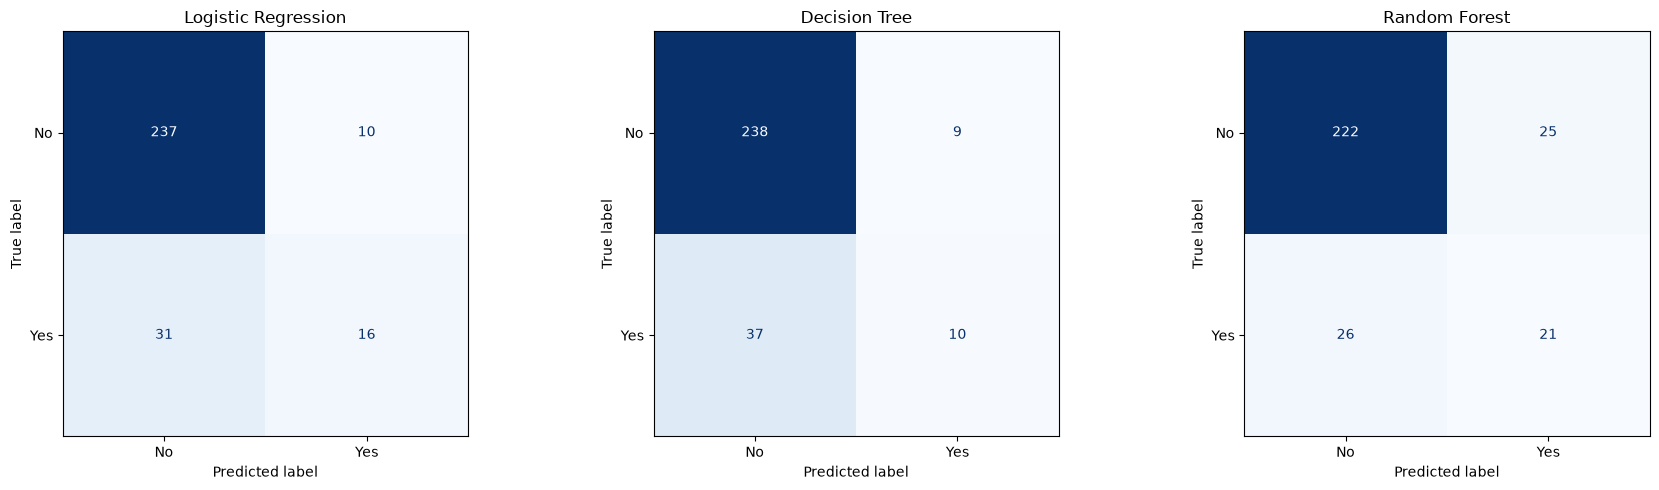

In [58]:
# Confusion Matrix visualize
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

models = [
    ("Logistic Regression", y_pred_logistic),
    ("Decision Tree", y_pred_tree),
    ("Random Forest", y_pred_rf)
]

for ax, (name, predictions) in zip(axes, models):

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    )

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No", "Yes"]
    ).plot(
        ax=ax,
        cmap="Blues",
        colorbar=False
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

Classification Report

In [59]:
print("LOGISTIC REGRESSION")
print(
    classification_report(
        y_test,
        y_pred_logistic,
        target_names=["No Attrition", "Attrition"],
        zero_division=0
    )
)

print("\nDECISION TREE")
print(
    classification_report(
        y_test,
        y_pred_tree,
        target_names=["No Attrition", "Attrition"],
        zero_division=0
    )
)

print("\nRANDOM FOREST")
print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=["No Attrition", "Attrition"],
        zero_division=0
    )
)

LOGISTIC REGRESSION
              precision    recall  f1-score   support

No Attrition       0.88      0.96      0.92       247
   Attrition       0.62      0.34      0.44        47

    accuracy                           0.86       294
   macro avg       0.75      0.65      0.68       294
weighted avg       0.84      0.86      0.84       294


DECISION TREE
              precision    recall  f1-score   support

No Attrition       0.87      0.96      0.91       247
   Attrition       0.53      0.21      0.30        47

    accuracy                           0.84       294
   macro avg       0.70      0.59      0.61       294
weighted avg       0.81      0.84      0.81       294


RANDOM FOREST
              precision    recall  f1-score   support

No Attrition       0.90      0.90      0.90       247
   Attrition       0.46      0.45      0.45        47

    accuracy                           0.83       294
   macro avg       0.68      0.67      0.67       294
weighted avg       0.83 

ROC Curve Compare

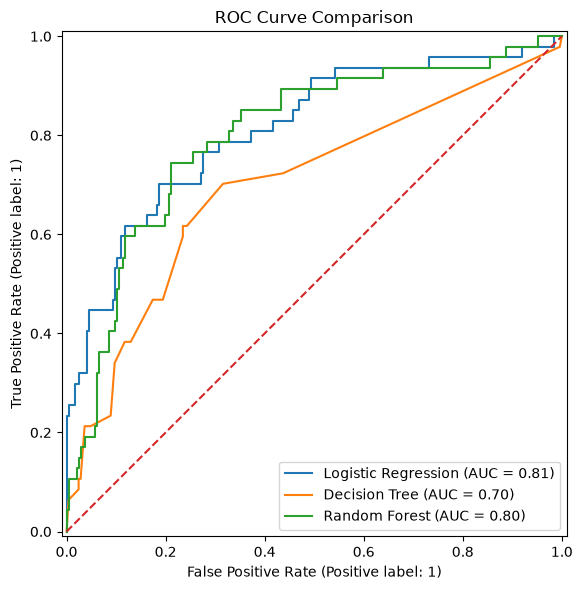

In [60]:
fig, ax = plt.subplots(figsize=(8, 6))

RocCurveDisplay.from_predictions(
    y_test,
    y_prob_logistic,
    name="Logistic Regression",
    ax=ax
)

RocCurveDisplay.from_predictions(
    y_test,
    y_prob_tree,
    name="Decision Tree",
    ax=ax
)

RocCurveDisplay.from_predictions(
    y_test,
    y_prob_rf,
    name="Random Forest",
    ax=ax
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random ranking"
)

ax.set_title("ROC Curve Comparison")
plt.tight_layout()
plt.show()

In [61]:
# Results
from pathlib import Path

results_dir = Path("../reports")
results_dir.mkdir(parents=True, exist_ok=True)

results_df.to_csv(
    results_dir / "model_comparison.csv",
    index=False
)

print("Model comparison results saved successfully!")

Model comparison results saved successfully!


Hyperparameter Tuning

In [62]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone

import pandas as pd
import numpy as np

In [63]:
# Define the Hyperparameter Search Space
param_distributions = {
    "model__n_estimators": [100, 200, 300, 400, 500],
    "model__max_depth": [None, 5, 10, 15, 20],
    "model__min_samples_split": [2, 5, 10, 15],
    "model__min_samples_leaf": [1, 2, 4, 6],
    "model__max_features": ["sqrt", "log2"],
    "model__class_weight": ["balanced", "balanced_subsample"]
}

In [64]:
# create Pipeline
tuning_pipeline = clone(random_forest_model)

print(tuning_pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'DailyRate',
                                                   'DistanceFromHome',
                                                   'Education',
                                                   'EnvironmentSatisfaction',
                                                   'HourlyRate',
                                                   'JobInvolvement', 'JobLevel',
                                                   'JobSatisfaction',
                                                   'MonthlyIncome

In [65]:
# Configure RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=30,
    scoring="f1",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

In [66]:
# Train the Hyperparameter Search
random_search.fit(X_train, y_train)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__class_weight': ['balanced', 'balanced_subsample'], 'model__max_depth': [None, 5, ...], 'model__max_features': ['sqrt', 'log2'], 'model__min_samples_leaf': [1, 2, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator

In [67]:
# Display the Best Hyperparameters
print("Best Hyperparameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation F1-Score:")
print(round(random_search.best_score_, 3))

Best Hyperparameters:
{'model__n_estimators': 500, 'model__min_samples_split': 10, 'model__min_samples_leaf': 2, 'model__max_features': 'sqrt', 'model__max_depth': 10, 'model__class_weight': 'balanced'}

Best Cross-Validation F1-Score:
0.532


In [68]:
# Evaluate the Tuned Model
best_model = random_search.best_estimator_

y_pred_tuned = best_model.predict(X_test)

y_prob_tuned = best_model.predict_proba(X_test)[:, 1]

In [69]:
# calculate the evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

tuned_results = {
    "Model": "Tuned Random Forest",
    "Accuracy": accuracy_score(y_test, y_pred_tuned),
    "Precision": precision_score(
        y_test, y_pred_tuned, zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_pred_tuned, zero_division=0
    ),
    "F1-Score": f1_score(
        y_test, y_pred_tuned, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_test, y_prob_tuned)
}

tuned_results_df = pd.DataFrame([tuned_results])

tuned_results_df.round(3)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Tuned Random Forest,0.83,0.473,0.553,0.51,0.786


In [71]:
# Compare the Tuned Model with Previous Models
all_results = pd.concat(
    [results_df, tuned_results_df],
    ignore_index=True
)

all_results = all_results.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

all_results.round(3)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Tuned Random Forest,0.830,0.473,0.553,0.510,0.786
1,Random Forest,0.827,0.457,0.447,0.452,0.800
2,Logistic Regression,0.861,0.615,0.340,0.438,0.812
3,Decision Tree,0.844,0.526,0.213,0.303,0.698


In [72]:
# Generate the Classification Report
print(
    classification_report(
        y_test,
        y_pred_tuned,
        target_names=["Employee Stays", "Employee Leaves"],
        zero_division=0
    )
)

                 precision    recall  f1-score   support

 Employee Stays       0.91      0.88      0.90       247
Employee Leaves       0.47      0.55      0.51        47

       accuracy                           0.83       294
      macro avg       0.69      0.72      0.70       294
   weighted avg       0.84      0.83      0.84       294



Evaluate the tuned mode

In [73]:
random_search.fit(X_train, y_train)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__class_weight': ['balanced', 'balanced_subsample'], 'model__max_depth': [None, 5, ...], 'model__max_features': ['sqrt', 'log2'], 'model__min_samples_leaf': [1, 2, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator

In [ ]:
best_model = random_search.best_estimator_

y_pred_tuned = best_model.predict(X_test)
y_prob_tuned = best_model.predict_proba(X_test)[:, 1]

In [74]:
# Calculate evaluation metric
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

tuned_results = {
    "Model": "Tuned Random Forest",
    "Accuracy": accuracy_score(y_test, y_pred_tuned),
    "Precision": precision_score(
        y_test, y_pred_tuned, zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_pred_tuned, zero_division=0
    ),
    "F1-Score": f1_score(
        y_test, y_pred_tuned, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_test, y_prob_tuned)
}

tuned_results_df = pd.DataFrame([tuned_results])

tuned_results_df.round(3)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Tuned Random Forest,0.83,0.473,0.553,0.51,0.786


In [75]:
# Compare all four models
all_results = pd.concat(
    [results_df, tuned_results_df],
    ignore_index=True
)

all_results = all_results.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

all_results.round(3)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Tuned Random Forest,0.830,0.473,0.553,0.510,0.786
1,Random Forest,0.827,0.457,0.447,0.452,0.800
2,Logistic Regression,0.861,0.615,0.340,0.438,0.812
3,Decision Tree,0.844,0.526,0.213,0.303,0.698


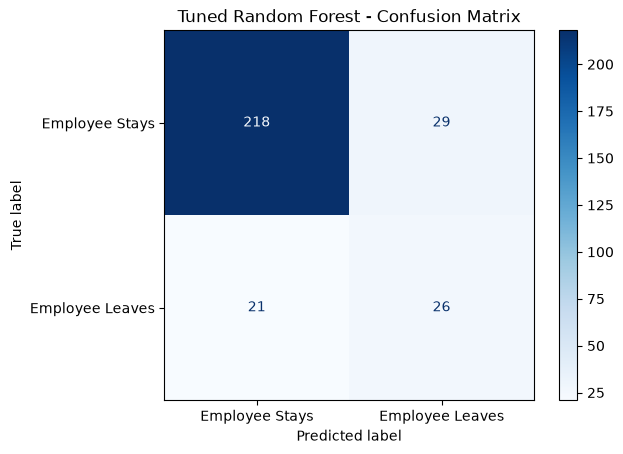

In [76]:
# confusion matrix
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tuned,
    display_labels=["Employee Stays", "Employee Leaves"],
    cmap="Blues"
)

plt.title("Tuned Random Forest - Confusion Matrix")
plt.show()

In [77]:

all_results.round(3)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Tuned Random Forest,0.830,0.473,0.553,0.510,0.786
1,Random Forest,0.827,0.457,0.447,0.452,0.800
2,Logistic Regression,0.861,0.615,0.340,0.438,0.812
3,Decision Tree,0.844,0.526,0.213,0.303,0.698


In [78]:
%pip install joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [79]:
all_results.round(3)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Tuned Random Forest,0.830,0.473,0.553,0.510,0.786
1,Random Forest,0.827,0.457,0.447,0.452,0.800
2,Logistic Regression,0.861,0.615,0.340,0.438,0.812
3,Decision Tree,0.844,0.526,0.213,0.303,0.698


In [80]:
best_model = random_search.best_estimator_

In [81]:
from pathlib import Path
# Create a Models Folder
models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

print("Models directory created successfully!")

Models directory created successfully!


In [83]:
import joblib

model_path = models_dir / "employee_attrition_model.joblib"

joblib.dump(best_model, model_path)

print("Model saved successfully!")
print("Saved location:", model_path.resolve())

Model saved successfully!
Saved location: C:\Users\MSII\OneDrive\Desktop\employee-attrition-prediction\models\employee_attrition_model.joblib


In [85]:
print(random_search.best_params_)

{'model__n_estimators': 500, 'model__min_samples_split': 10, 'model__min_samples_leaf': 2, 'model__max_features': 'sqrt', 'model__max_depth': 10, 'model__class_weight': 'balanced'}


In [84]:
loaded_model = joblib.load(model_path)

print("Model loaded successfully!")
print(type(loaded_model))

Model loaded successfully!
<class 'sklearn.pipeline.Pipeline'>


In [86]:
best_model = random_search.best_estimator_

print("Best model selected successfully!")
print(best_model)

Best model selected successfully!
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'DailyRate',
                                                   'DistanceFromHome',
                                                   'Education',
                                                   'EnvironmentSatisfaction',
                                                   'HourlyRate',
                                                   'JobInvolvement', 'JobLevel',
                                                   'JobSatisfaction',
                               

In [87]:
# save the model
import joblib

model_path = models_dir / "employee_attrition_model.joblib"

joblib.dump(best_model, model_path)

print("Model saved successfully!")
print("Saved location:", model_path.resolve())

Model saved successfully!
Saved location: C:\Users\MSII\OneDrive\Desktop\employee-attrition-prediction\models\employee_attrition_model.joblib


In [88]:
print("Model file exists:", model_path.exists())
# verify the file exist

Model file exists: True


In [89]:
# load the save model
import joblib

loaded_model = joblib.load(model_path)

print("Model loaded successfully!")
print(type(loaded_model))

Model loaded successfully!
<class 'sklearn.pipeline.Pipeline'>


In [90]:
# make predicion
sample_employee = X_test.iloc[[0]]

prediction = loaded_model.predict(sample_employee)
probability = loaded_model.predict_proba(sample_employee)[0][1]

if prediction[0] == 1:
    print("Prediction: Employee may leave")
else:
    print("Prediction: Employee may stay")

print(f"Attrition probability: {probability:.2%}")

Prediction: Employee may leave
Attrition probability: 73.28%


In [91]:
# Verify the loaded model
import numpy as np

original_predictions = best_model.predict(X_test)
loaded_predictions = loaded_model.predict(X_test)

print(
    "Predictions match:",
    np.array_equal(original_predictions, loaded_predictions)
)

Predictions match: True


In [92]:
# Save Model Metadata
import json

metadata = {
    "project": "Employee Attrition Prediction",
    "model_type": "Tuned Random Forest",
    "target_column": "Attrition",
    "target_mapping": {
        "No": 0,
        "Yes": 1
    },
    "input_features": X_train.columns.tolist(),
    "best_hyperparameters": random_search.best_params_,
    "best_cross_validation_f1": float(random_search.best_score_)
}

metadata_path = models_dir / "model_metadata.json"

with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=4)

print("Model metadata saved successfully!")
print("Location:", metadata_path.resolve())

Model metadata saved successfully!
Location: C:\Users\MSII\OneDrive\Desktop\employee-attrition-prediction\models\model_metadata.json


In [93]:
with open(metadata_path, "r", encoding="utf-8") as file:
    saved_metadata = json.load(file)

print(json.dumps(saved_metadata, indent=4))

{
    "project": "Employee Attrition Prediction",
    "model_type": "Tuned Random Forest",
    "target_column": "Attrition",
    "target_mapping": {
        "No": 0,
        "Yes": 1
    },
    "input_features": [
        "Age",
        "BusinessTravel",
        "DailyRate",
        "Department",
        "DistanceFromHome",
        "Education",
        "EducationField",
        "EnvironmentSatisfaction",
        "Gender",
        "HourlyRate",
        "JobInvolvement",
        "JobLevel",
        "JobRole",
        "JobSatisfaction",
        "MaritalStatus",
        "MonthlyIncome",
        "MonthlyRate",
        "NumCompaniesWorked",
        "OverTime",
        "PercentSalaryHike",
        "PerformanceRating",
        "RelationshipSatisfaction",
        "StockOptionLevel",
        "TotalWorkingYears",
        "TrainingTimesLastYear",
        "WorkLifeBalance",
        "YearsAtCompany",
        "YearsInCurrentRole",
        "YearsSinceLastPromotion",
        "YearsWithCurrManager"
    